In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [12]:
df=pd.read_csv("height-weight.csv")

In [13]:
df.head()

,Weight,Height
0,45,120
1,58,135
2,48,123
3,60,145
4,70,160


In [15]:
plt.scatter(df["Weight"],df["Height"])
plt.xlabel("Weight")
plt.ylabel("Height")


KeyError: 'Height'

In [ ]:
df.corr()

,Weight,Height
Weight,1.000000,0.931142
Height,0.931142,1.000000


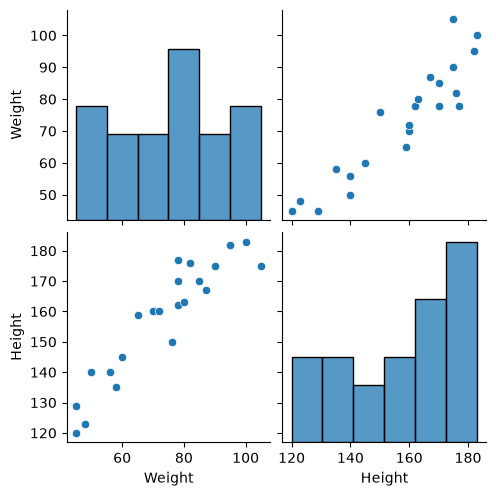

In [ ]:
import seaborn as sns
sns.pairplot(df)

In [ ]:
X=df[["Weight"]]#Independent Feature
y=df["Height"]#Dependent Feature


In [ ]:
X_Series=df["Weight"]
X_Series.shape

(23,)

In [ ]:
#Train Test Split
from sklearn.model_selection import train_test_split


In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=32)


In [ ]:
#Standaridization (z-score)
from sklearn.preprocessing import StandardScaler

In [ ]:
scalar=StandardScaler()

In [ ]:
X_train=scalar.fit_transform(X_train)
X_train

array([[ 0.16616658],
       [-1.77590532],
       [ 1.46088118],
       [-1.59935333],
       [ 1.7551345 ],
       [ 0.04846525],
       [-1.01084669],
       [-0.1869374 ],
       [-0.30463873],
       [ 0.16616658],
       [ 0.40156923],
       [-1.12854802],
       [-0.89314536],
       [ 0.87237454],
       [ 0.69582255],
       [ 0.16616658],
       [ 1.16662786]])

In [ ]:
X_test=scalar.fit_transform(X_test)
X_test

array([[-1.481652  ],
       [ 1.16662786],
       [ 0.57812122],
       [-1.77590532],
       [-0.59889205],
       [ 0.28386791]])

In [ ]:
#Applay Sipmle Linear Regression
from sklearn.linear_model import LinearRegression
regression=LinearRegression(n_jobs=-1)

In [ ]:
regression.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",-1
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [ ]:
#Coefficient(slope) and intercept
print("Coefficient:",regression.coef_)
print("Intercept:",regression.intercept_)

Coefficient: [17.98590315]
Intercept: 158.8235294117647


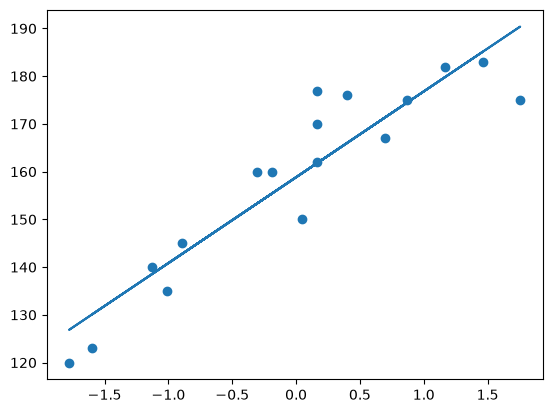

In [ ]:
plt.scatter(X_train,y_train)
plt.plot(X_train,regression.predict(X_train))

In [ ]:
#Prediction for test data
y_pred=regression.predict(X_test)

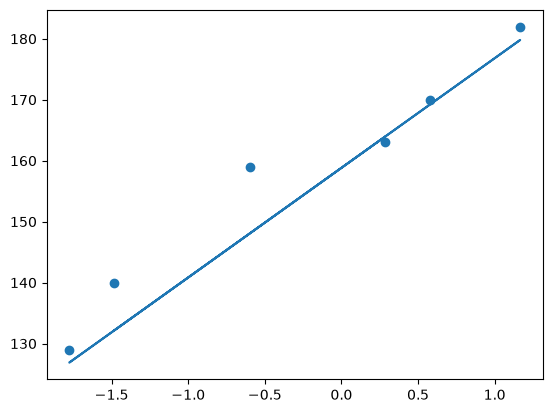

In [ ]:
plt.scatter(X_test,y_test)
plt.plot(X_test,y_pred)

In [ ]:
#Performance Metrics
from sklearn.metrics import mean_absolute_error,mean_squared_error

In [ ]:
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
rmse=np.sqrt(mse)
print(f"Mean Absolute Error:{mae}")
print(f"Mean Squared Error:{mse}")
print(f"Root Mean Absolute Error:{rmse}")

Mean Absolute Error:4.13205662879696
Mean Squared Error:31.977036032987204
Root Mean Absolute Error:5.654824138113157


In [ ]:
from sklearn.metrics import r2_score

In [ ]:
score=r2_score(y_test,y_pred)
score

0.899381758833359

In [ ]:
#Display Adjusted Rsquare 
1-(1-score)*(len(y_test)-1)/(len(y_test)-X_test.shape[1]-1)

0.8742271985416987

In [ ]:
#OLS
import statsmodels.api as sm

In [ ]:
model=sm.OLS(y_train,X_train).fit()

In [ ]:
print(model.summary())

                                 OLS Regression Results                                
Dep. Variable:                 Height   R-squared (uncentered):                   0.013
Model:                            OLS   Adj. R-squared (uncentered):             -0.049
Method:                 Least Squares   F-statistic:                             0.2047
Date:                Wed, 11 Nov 2026   Prob (F-statistic):                       0.657
Time:                        10:06:17   Log-Likelihood:                         -110.29
No. Observations:                  17   AIC:                                      222.6
Df Residuals:                      16   BIC:                                      223.4
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------

In [ ]:
regression.predict(scalar.transform([[70]]))

NameError: name 'regression' is not defined